In [1]:
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error, roc_auc_score
from sklearn.model_selection import (
GridSearchCV, KFold, StratifiedKFold, cross_val_score, train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

In [2]:
cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")
X_c = cancer.drop(columns=["id", "diagnosis", "Unnamed: 32"], errors="ignore")
y_c = (cancer["diagnosis"] == "M").astype(int)
Xc_train, Xc_valid, yc_train, yc_valid = train_test_split(
X_c, y_c, test_size=0.25, random_state=42, stratify=y_c
)


k= 1 cross-validated ROC AUC = 0.946
k= 3 cross-validated ROC AUC = 0.984
k= 5 cross-validated ROC AUC = 0.985
k= 7 cross-validated ROC AUC = 0.987
k=11 cross-validated ROC AUC = 0.988
k=21 cross-validated ROC AUC = 0.988
selected k: 11


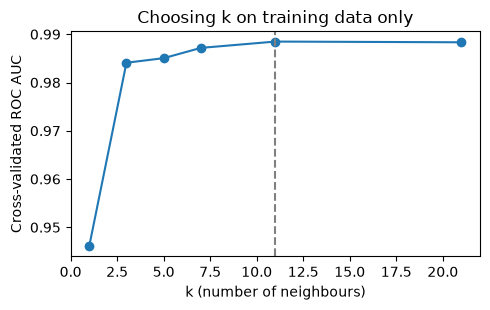

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_values = [1, 3, 5, 7, 11, 21]
cv_scores = {}
for k in k_values:
    candidate = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=k, weights="distance")),])
    scores = cross_val_score(candidate, Xc_train, yc_train, cv=cv, scoring="roc_auc")
    cv_scores[k] = scores.mean()
    print(f"k={k:2d} cross-validated ROC AUC = {scores.mean():.3f}")
    
best_k = max(cv_scores, key=lambda k: cv_scores[k])
print("selected k:", best_k)
plt.figure(figsize=(5, 3.2))
plt.plot(k_values, [cv_scores[k] for k in k_values], marker="o")
plt.axvline(best_k, linestyle="--", color="grey")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Cross-validated ROC AUC")
plt.title("Choosing k on training data only")
plt.tight_layout()
plt.show()


In [4]:
models = {
"KNN": Pipeline([
("scale", StandardScaler()),
("model", KNeighborsClassifier(n_neighbors=best_k, weights="distance")),
]),
"GaussianNB": Pipeline([
("scale", StandardScaler()),
("model", GaussianNB()),
]),
}
for name, model in models.items():
    model.fit(Xc_train, yc_train)
    pred = model.predict(Xc_valid)
    prob_c = model.predict_proba(Xc_valid)[:, 1]
    print(f"{name:10s} accuracy={accuracy_score(yc_valid, pred):.3f} "
        f"roc_auc={roc_auc_score(yc_valid, prob_c):.3f}")


KNN        accuracy=0.958 roc_auc=0.986
GaussianNB accuracy=0.944 roc_auc=0.992


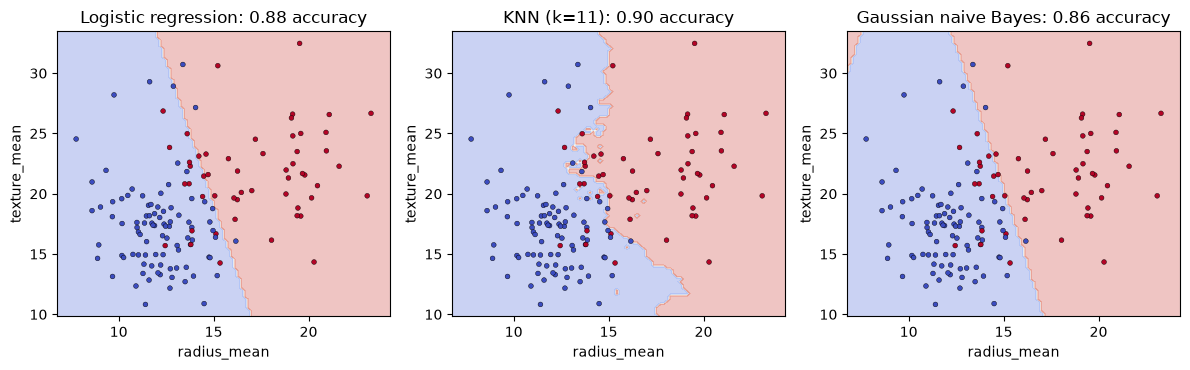

In [5]:
two = ["radius_mean", "texture_mean"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (name, estimator) in zip(axes, [
    ("Logistic regression", LogisticRegression(max_iter=2000)),
    (f"KNN (k={best_k})", KNeighborsClassifier(n_neighbors=best_k, weights="distance")),
    ("Gaussian naive Bayes", GaussianNB()),
    ]):
    small = Pipeline([("scale", StandardScaler()), ("model", estimator)])
    small.fit(Xc_train[two], yc_train)
    DecisionBoundaryDisplay.from_estimator(small, Xc_valid[two], ax=ax, alpha=0.3,
    response_method="predict", cmap="coolwarm")
    ax.scatter(Xc_valid[two[0]], Xc_valid[two[1]], c=yc_valid, cmap="coolwarm",
    s=12, edgecolor="k", linewidth=0.3)
    ax.set_title(f"{name}: {accuracy_score(yc_valid, small.predict(Xc_valid[two])):.2f} accuracy")
    ax.set_xlabel("radius_mean")
    ax.set_ylabel("texture_mean")
plt.tight_layout()
plt.show()


In [6]:
titanic = pd.read_csv(DATA / "titanic_dataset.csv")
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
t_num = ["Age", "SibSp", "Parch", "Fare"]
t_cat = ["Pclass", "Sex", "Embarked"]
X_t = titanic[features]
y_t = titanic["Survived"]
tree_preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), t_num),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), t_cat),
    ])
Xt_train, Xt_valid, yt_train, yt_valid = train_test_split(
    X_t, y_t, test_size=0.25, random_state=42, stratify=y_t
)
tree = Pipeline([
    ("preprocess", tree_preprocess),
    ("tree", DecisionTreeClassifier(max_depth=4, min_samples_leaf=12, random_state=42)),
])
tree.fit(Xt_train, yt_train)
print("training accuracy:", round(accuracy_score(yt_train, tree.predict(Xt_train)), 3))
print("validation accuracy:", round(accuracy_score(yt_valid, tree.predict(Xt_valid)), 3))

training accuracy: 0.843
validation accuracy: 0.767


|--- cat__Sex_female <= 0.50
|   |--- num__Age <= 3.50
|   |   |--- class: 1
|   |--- num__Age >  3.50
|   |   |--- cat__Pclass_1 <= 0.50
|   |   |   |--- num__Fare <= 48.09
|   |   |   |   |--- class: 0
|   |   |   |--- num__Fare >  48.09
|   |   |   |   |--- class: 0
|   |   |--- cat__Pclass_1 >  0.50
|   |   |   |--- num__Age <= 53.00
|   |   |   |   |--- class: 0
|   |   |   |--- num__Age >  53.00
|   |   |   |   |--- class: 0
|--- cat__Sex_female >  0.50
|   |--- cat__Pclass_3 <= 0.50
|   |   |--- num__Fare <= 28.86
|   |   |   |--- num__Age <= 37.00
|   |   |   |   |--- class: 1
|   |   |   |--- num__Age >  37.00
|   |   |   |   |--- class: 1
|   |   |--- num__Fare >  28.86
|   |   |   |--- num__Parch <= 1.50
|   |   |   |   |--- class: 1
|   |   |   |--- num__Parch >  1.50
|   |   |   |   |--- class: 1
|   |--- cat__Pclass_3 >  0.50
|   |   |--- num__Fare <= 7.89
|   |   |   |--- cat__Embarked_S <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- cat__Embarked_S >  0.50
|   |

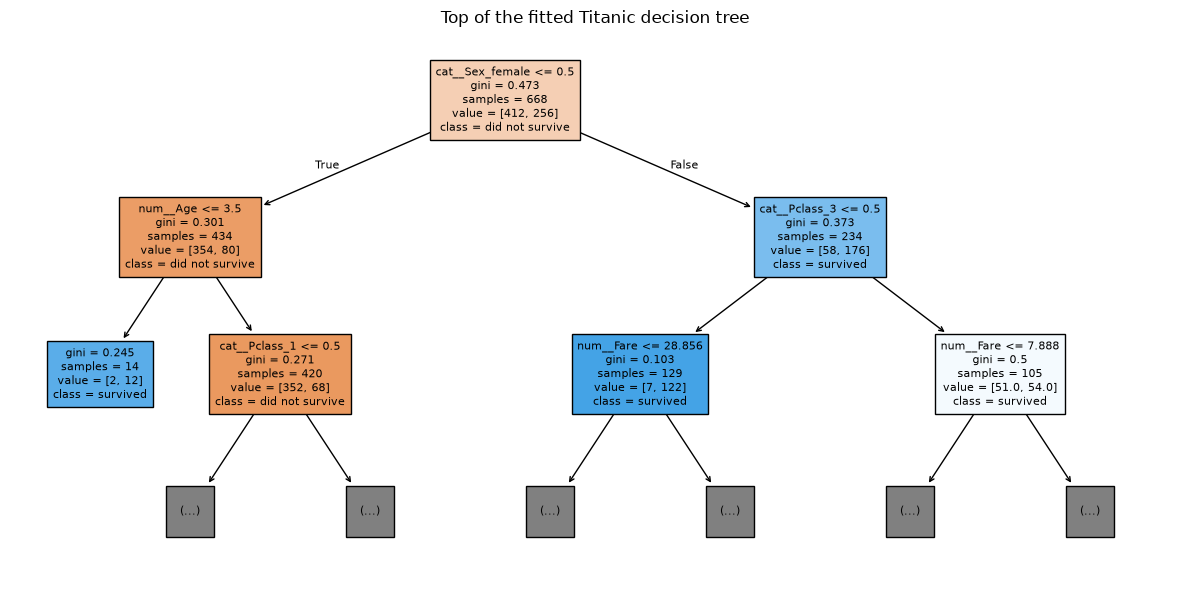

In [7]:
feature_names = list(tree.named_steps["preprocess"].get_feature_names_out())
print(export_text(tree.named_steps["tree"], feature_names=feature_names, max_depth=3))
plt.figure(figsize=(12, 6))
plot_tree(tree.named_steps["tree"], feature_names=feature_names,
class_names=["did not survive", "survived"], max_depth=2, filled=True, fontsize=8)
plt.title("Top of the fitted Titanic decision tree")
plt.tight_layout()
plt.show()


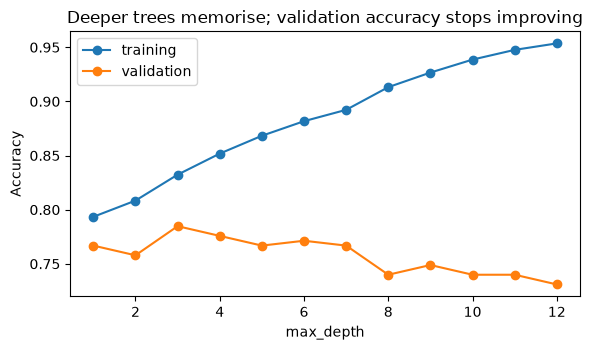

In [8]:
depths = list(range(1, 13))
train_acc, valid_acc = [], []
for depth in depths:
    t = Pipeline([
    ("preprocess", tree_preprocess),
    ("tree", DecisionTreeClassifier(max_depth=depth, random_state=42)),
    ]).fit(Xt_train, yt_train)
    train_acc.append(accuracy_score(yt_train, t.predict(Xt_train)))
    valid_acc.append(accuracy_score(yt_valid, t.predict(Xt_valid)))
plt.figure(figsize=(6, 3.6))
plt.plot(depths, train_acc, marker="o", label="training")
plt.plot(depths, valid_acc, marker="o", label="validation")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Deeper trees memorise; validation accuracy stops improving")
plt.legend()
plt.tight_layout()
plt.show()


random_forest      CV log-RMSE = 0.1382 +/- 0.0118
gradient_boosting  CV log-RMSE = 0.1273 +/- 0.0141


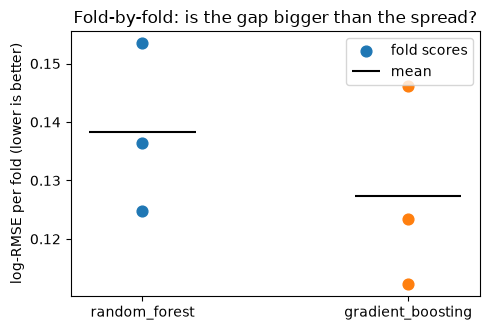

In [9]:
ames = pd.read_csv(DATA / "ames_housing_dataset.csv")
X_a = ames.drop(columns=["SalePrice", "Order", "PID"], errors="ignore") # identifiers out
y_a = np.log1p(ames["SalePrice"])
ames_preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), X_a.select_dtypes(include="number").columns),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
]), X_a.select_dtypes(exclude="number").columns),
])
ensembles = {
"random_forest": RandomForestRegressor(
n_estimators=150, max_features=0.8, min_samples_leaf=2, random_state=42, n_jobs=-1
),
"gradient_boosting": GradientBoostingRegressor(
n_estimators=150, learning_rate=0.05, max_depth=3, loss="huber", random_state=42
),
}
cv3 = KFold(n_splits=3, shuffle=True, random_state=42)
cv_rmse = {}
for name, estimator in ensembles.items():
    pipe = Pipeline([("preprocess", ames_preprocess), ("model", estimator)])
    neg_mse = cross_val_score(pipe, X_a, y_a, cv=cv3, scoring="neg_mean_squared_error")
    cv_rmse[name] = np.sqrt(-neg_mse)
    print(f"{name:18s} CV log-RMSE = {cv_rmse[name].mean():.4f} +/- {cv_rmse[name].std():.4f}")
plt.figure(figsize=(5, 3.4))
for i, (name, values) in enumerate(cv_rmse.items()):
    if i == 0:
        plt.scatter([i] * len(values), values, s=60, label="fold scores")
        plt.hlines(values.mean(), i - 0.2, i + 0.2, color="black", label="mean")
    else:
        plt.scatter([i] * len(values), values, s=60)
        plt.hlines(values.mean(), i - 0.2, i + 0.2, color="black")
plt.xticks(range(len(cv_rmse)), list(cv_rmse))
plt.ylabel("log-RMSE per fold (lower is better)")
plt.title("Fold-by-fold: is the gap bigger than the spread?")
plt.legend()
plt.tight_layout()
plt.show()



random_forest      MAE = 0.432 RMSE = 0.565
gradient_boosting  MAE = 0.476 RMSE = 0.597


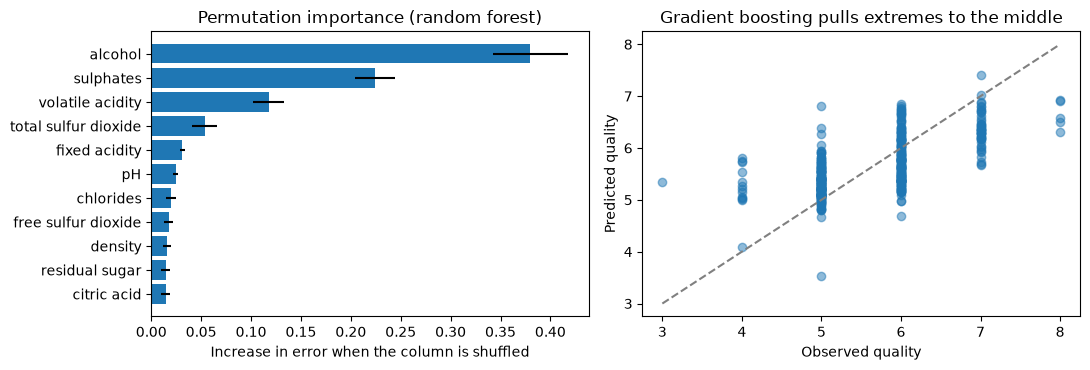

In [10]:
wine = pd.read_csv(DATA / "red_wine_quality_dataset.csv")
X_w = wine.drop(columns="quality")
y_w = wine["quality"]
Xw_train, Xw_valid, yw_train, yw_valid = train_test_split(X_w, y_w, test_size=0.25, random_state=42)
wine_models = {
"random_forest": RandomForestRegressor(n_estimators=400, min_samples_leaf=2,
random_state=42, n_jobs=-1),
"gradient_boosting": GradientBoostingRegressor(random_state=42),
}
wine_pred = {}
for name, model in wine_models.items():
    model.fit(Xw_train, yw_train)
    wine_pred[name] = model.predict(Xw_valid)
    print(f"{name:18s} MAE = {mean_absolute_error(yw_valid, wine_pred[name]):.3f} "
        f"RMSE = {np.sqrt(mean_squared_error(yw_valid, wine_pred[name])):.3f}")
    
importance = permutation_importance(
    wine_models["random_forest"], Xw_valid, yw_valid, n_repeats=10, random_state=42, n_jobs=-1
)   
ranked = pd.Series(
    importance["importances_mean"],
    index=X_w.columns
).sort_values()

spread = (
    pd.Series(
        np.asarray(importance["importances_std"], dtype=float),
        index=X_w.columns,
    )
    .reindex(ranked.index)
    .to_numpy()
)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].barh(ranked.index, ranked.values, xerr=spread)
axes[0].set_xlabel("Increase in error when the column is shuffled")
axes[0].set_title("Permutation importance (random forest)")
axes[1].scatter(yw_valid, wine_pred["gradient_boosting"], alpha=0.5)
axes[1].plot([3, 8], [3, 8], linestyle="--", color="grey")
axes[1].set_xlabel("Observed quality")
axes[1].set_ylabel("Predicted quality")
axes[1].set_title("Gradient boosting pulls extremes to the middle")
plt.tight_layout()
plt.show()


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
X_c, y_c, test_size=0.25, random_state=42, stratify=y_c
)
svm_pipe = Pipeline([("scale", StandardScaler()), ("model", SVC())])
search = GridSearchCV(
    svm_pipe,
    param_grid={
        "model__kernel": ["linear", "rbf"],
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", 0.01, 0.1],
    },
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="roc_auc",
    n_jobs=-1,
)
search.fit(X_train, y_train)
score = search.decision_function(X_test)
pred = search.predict(X_test)
print("best parameters:", search.best_params_)
print("cross-validated ROC AUC:", round(search.best_score_, 3))
print("test accuracy:", round(accuracy_score(y_test, pred), 3))
print("test ROC AUC:", round(roc_auc_score(y_test, score), 3))


best parameters: {'model__C': 10, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
cross-validated ROC AUC: 0.995
test accuracy: 0.979
test ROC AUC: 0.997


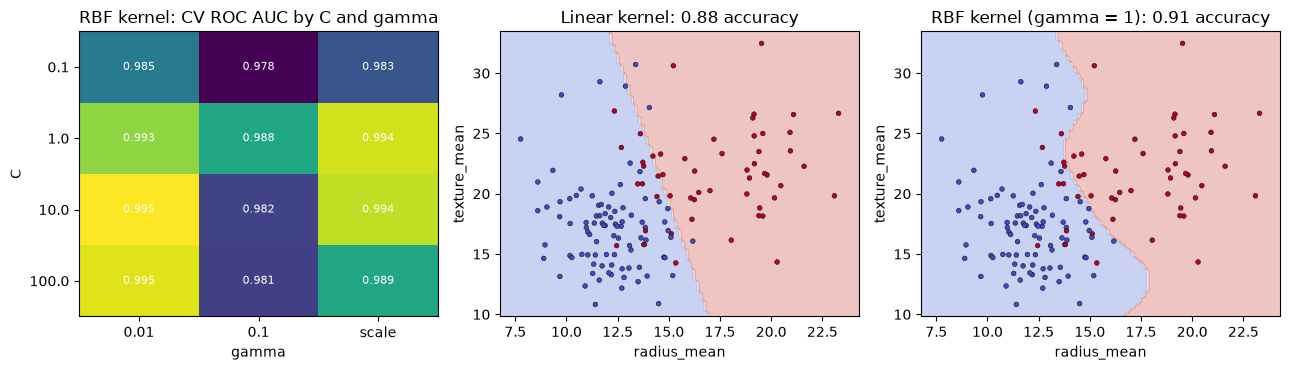

In [12]:
results = pd.DataFrame(search.cv_results_)
rbf = results[results["param_model__kernel"] == "rbf"].copy()
rbf["gamma"] = rbf["param_model__gamma"].astype(str)
grid = rbf.pivot(index="param_model__C", columns="gamma", values="mean_test_score")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
im = axes[0].imshow(grid.values, cmap="viridis", aspect="auto")
axes[0].set_xticks(range(len(grid.columns)), grid.columns)
axes[0].set_yticks(range(len(grid.index)), grid.index)
axes[0].set_xlabel("gamma")
axes[0].set_ylabel("C")
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        axes[0].text(j, i, f"{grid.values[i, j]:.3f}", ha="center", va="center", color="white", fontsize=8)
axes[0].set_title("RBF kernel: CV ROC AUC by C and gamma")
for ax, (title, estimator) in zip(axes[1:], [
    ("Linear kernel", SVC(kernel="linear", C=1)),
    ("RBF kernel (gamma = 1)", SVC(kernel="rbf", C=1, gamma=1.0)),
]):
    small = Pipeline([("scale", StandardScaler()), ("model", estimator)]).fit(X_train[two], y_train)
    DecisionBoundaryDisplay.from_estimator(small, X_test[two], ax=ax, alpha=0.3,
    response_method="predict", cmap="coolwarm")
    ax.scatter(X_test[two[0]], X_test[two[1]], c=y_test, cmap="coolwarm",
    s=12, edgecolor="k", linewidth=0.3)
    ax.set_title(f"{title}: {accuracy_score(y_test, small.predict(X_test[two])):.2f} accuracy")
    ax.set_xlabel("radius_mean")
    ax.set_ylabel("texture_mean")
plt.tight_layout()
plt.show()


In [13]:
model_path = MODELS / "breast_cancer_svm.joblib"
joblib.dump(search.best_estimator_, model_path)
loaded = joblib.load(model_path)
same = np.array_equal(loaded.predict(X_test), pred)
print("file size (KB):", round(model_path.stat().st_size / 1024, 1))
print("reloaded model reproduces the test predictions:", same)


file size (KB): 16.5
reloaded model reproduces the test predictions: True
